In [103]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
import scipy.stats as stats

# Генерація набору даних для Варіанта 1 (Київ)
np.random.seed(42)
city = "Київ"
mean_temp = 9.5
amplitude = 14
hum_base = 74

rows = []
for month in range(1, 13):
    temp = mean_temp + amplitude * np.cos((month - 7) / 12 * 2 * np.pi) + np.random.normal(0, 1.0)
    humidity = hum_base + np.random.normal(0, 5.0)
    if temp < 8:
        opal_days = 30
    elif temp < 12:
        opal_days = 15
    else:
        opal_days = 0

    cost = (
        200
        - 9.0 * temp
        + 0.6 * humidity
        + 2.5 * opal_days
        + np.random.normal(0, 15)
    )
    rows.append({
        "місто": city, "місяць": month,
        "температура": round(temp, 1),
        "вологість": round(humidity, 1),
        "опалювальні_дні": opal_days,
        "витрати_на_опалення": round(cost, 1),
    })

heating = pd.DataFrame(rows)
print("Перші рядки згенерованого набору heating:")
display(heating.head())

Перші рядки згенерованого набору heating:


,місто,місяць,температура,вологість,опалювальні_дні,витрати_на_опалення
0,Київ,1,-4.0,73.3,30,364.7
1,Київ,2,-1.1,72.8,30,325.1
2,Київ,3,4.1,77.8,30,277.9
3,Київ,4,10.0,71.7,15,183.1
4,Київ,5,16.7,64.4,0,62.1


In [104]:
# Завдання 1. Підготовка даних та побудова моделі OLS (2 предиктори)
X1 = sm.add_constant(heating[["температура", "вологість"]])
y = heating["витрати_на_опалення"]

model1 = sm.OLS(y, X1).fit()
print(model1.summary())

r2_1 = model1.rsquared
adj_r2_1 = model1.rsquared_adj
print(f"\nЗвичайний R² (модель 1): {r2_1:.4f}")
print(f"Adjusted R² (модель 1): {adj_r2_1:.4f}")

                             OLS Regression Results                            
Dep. Variable:     витрати_на_опалення   R-squared:                       0.976
Model:                             OLS   Adj. R-squared:                  0.970
Method:                  Least Squares   F-statistic:                     179.6
Date:                 Mon, 12 Oct 2026   Prob (F-statistic):           5.58e-08
Time:                         23:07:35   Log-Likelihood:                -52.453
No. Observations:                   12   AIC:                             110.9
Df Residuals:                        9   BIC:                             112.4
Df Model:                            2                                         
Covariance Type:             nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         223.1684    122.718      1

In [105]:
# Завдання 3. Обчислення VIF
vif_data = pd.DataFrame()
vif_data["Предиктор"] = X1.columns
vif_data["VIF"] = [variance_inflation_factor(X1.values, i) for i in range(X1.shape[1])]
display(vif_data)

,Предиктор,VIF
0,const,1.00000
1,температура,1.55295
2,вологість,1.55295


In [106]:
# Завдання 4. Модель із трьома предикторами
X2 = sm.add_constant(heating[["температура", "вологість", "опалювальні_дні"]])
model2 = sm.OLS(y, X2).fit()

print(f"Модель 1 (2 предиктора): R² = {model1.rsquared:.4f}, Adj R² = {model1.rsquared_adj:.4f}")
print(f"Модель 2 (3 предиктора): R² = {model2.rsquared:.4f}, Adj R² = {model2.rsquared_adj:.4f}")

Модель 1 (2 предиктора): R² = 0.9756, Adj R² = 0.9701
Модель 2 (3 предиктора): R² = 0.9916, Adj R² = 0.9884


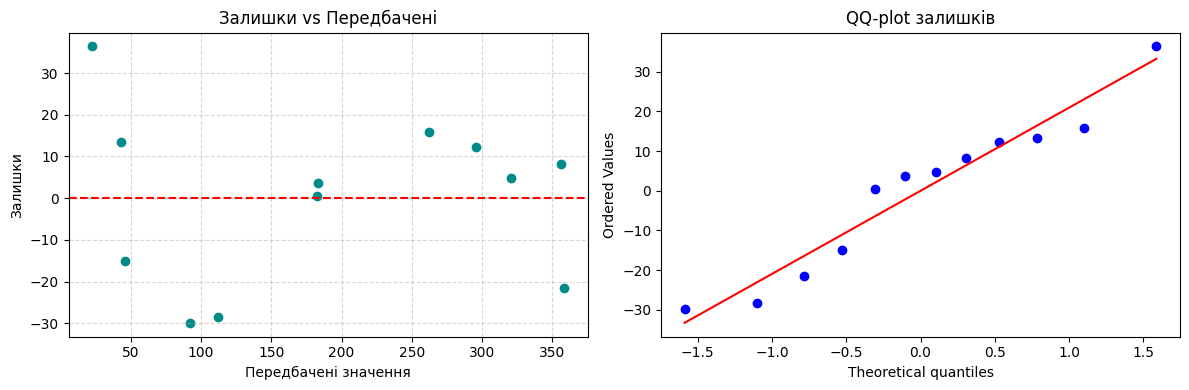

Тест Шапіро-Вілка: статистика = 0.9388, p-value = 0.4828


In [107]:
# Завдання 5. Графік залишків, QQ-plot та Шапіро-Вілк
fitted = model1.fittedvalues
residuals = model1.resid

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# 1. Графік залишків проти передбачених
ax1.scatter(fitted, residuals, color="darkcyan")
ax1.axhline(0, color="red", linestyle="--")
ax1.set_xlabel("Передбачені значення")
ax1.set_ylabel("Залишки")
ax1.set_title("Залишки vs Передбачені")
ax1.grid(True, linestyle="--", alpha=0.5)

# 2. QQ-plot
stats.probplot(residuals, dist="norm", plot=ax2)
ax2.set_title("QQ-plot залишків")

plt.tight_layout()
plt.show()

# Критерій Шапіро-Вілка на нормальність залишків
shapiro_stat, shapiro_p = stats.shapiro(residuals)
print(f"Тест Шапіро-Вілка: статистика = {shapiro_stat:.4f}, p-value = {shapiro_p:.4f}")

In [108]:
# Завдання 6. Проста регресія (тільки температура) проти множинної
X_simple = sm.add_constant(heating[["температура"]])
model_simple = sm.OLS(y, X_simple).fit()

print(f"Проста регресія (1 предиктор): R² = {model_simple.rsquared:.4f}")
print(f"Множинна регресія (2 предиктори): Adjusted R² = {model1.rsquared_adj:.4f}")

Проста регресія (1 предиктор): R² = 0.9742
Множинна регресія (2 предиктори): Adjusted R² = 0.9701


### Відповіді на контрольні запитання:

1. **Чому `sm.add_constant()` є обов'язковим кроком перед `sm.OLS()`:**
   - Функція додає до матриці предикторів стовпець одиниць, що відповідає вільному члену (інтерсепту, або $\beta_0$) у рівнянні регресії. Якщо його пропустити, лінія регресії примусово проходитиме через початок координат (через нуль), що серйозно спотворить усі інші коефіцієнти моделі.

2. **Відмінність коефіцієнта множинної регресії від простої:**
   - Коефіцієнт простої регресії відображає загальний зв'язок між однією змінною та відгуком без урахування інших чинників. Коефіцієнт множинної регресії оцінює ефект предиктора «за інших рівних умов» (контролюючи, тобто фіксуючи вплив усіх інших предикторів у моделі).

3. **Чому звичайний $R^2$ не може зменшитися при додаванні нового предиктора:**
   - Формула звичайного $R^2$ базується виключно на зменшенні залишкової суми квадратів ($\text{SS}_{\text{res}}$). Додавання будь-якого предиктора, навіть випадкового чи безглуздого, математично не може збільшити залишки (або залишає їх на тому ж рівні, або зменшує), тому $R^2$ завжди зростає або залишається незмінним, що робить його непридатним для порівняння моделей різної складності.

4. **Що означає VIF предиктора (близько 1 та вище 10):**
   - VIF (Variance Inflation Factor) показує, у скільки разів збільшується дисперсія коефіцієнта через мультиколінеарність. VIF близько 1 означає повну відсутність лінійного зв'язку предиктора з іншими. VIF вище 10 сигналізує про критичну мультиколінеарність, через яку оцінки коефіцієнтів стають нестабільними та неточними — у такому разі проблемний предиктор вилучають або об'єднують з іншими.